# 07 – Drift-aware retraining

**Project:** Energy-Aware Early Fault Detection in Semiconductor Wafer Fabrication (UCI SECOM)

The final random forest from 05 was fitted once on July–September wafers. On the test period it missed 14 of
17 faults, 11 of them between 4 and 7 October, when a failure pattern that never appeared in training occurred
(06, section 4). A fab does not have to keep a model frozen: every wafer gets its line-test label shortly after
it is scored, so the model can be **refitted on all wafers labelled so far** before each new block of production,
with **recency weights** so that the newest wafers count most.

This notebook:

1. compares refit schemes (static, weekly, daily) and recency half-lives **on the training set only**;
2. applies a selection rule fixed in advance and scores the chosen scheme **once** on the 313 test wafers;
3. checks which of the static model's missed faults are now caught, and at what cost in false alarms;
4. recomputes the energy, emissions and economic estimates of 06 for the retrained system.

**Selection rule (fixed before running):** on the 1000 out-of-fold training wafers (18 Aug – 2 Oct, 48 fails),
choose the candidate with the lowest normalised energy cost at 10 : 1 (threshold tuned on the same scores, as
in 05), tie-break on PR-AUC, and adopt it only if it beats the static random forest.
Model settings (random forest, class weights, ANOVA top 20, tuned hyperparameters from 04) are unchanged.

In [1]:
import sys
from pathlib import Path
ROOT = Path.cwd().resolve().parent if Path.cwd().name == 'notebooks' else Path.cwd().resolve()
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import json, math, time, warnings
warnings.filterwarnings('ignore', category=UserWarning)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.colors import LinearSegmentedColormap
from imblearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_selection import SelectKBest, f_classif

from src.config import RANDOM_STATE, MODELS_DIR, OUTPUTS_DIR
from src.data_loader import load_secom, split_xy
from src.preprocessing import time_train_test_split, preprocessing_steps
from src.validation import time_cv
from src.cost_metric import C_FN, C_FP, COST_RATIOS, best_threshold, evaluate, flag_nothing_cost
from src.retraining import rolling_scores, static_fold_scores
from src.plotting import (apply_style, save_fig, CATEGORICAL, SEQUENTIAL_BLUES, REF_LINE_COLOR,
                          TEXT_PRIMARY, TEXT_SECONDARY, SURFACE, PASS_COLOR, FAIL_COLOR)

np.random.seed(RANDOM_STATE)
apply_style()

df = load_secom()
train_df, test_df = time_train_test_split(df, test_size=0.2)
X_all, y_all = split_xy(df)
times = df['timestamp']
X_train, y_train = split_xy(train_df)
n_train = len(train_df)
test_pos = np.arange(n_train, len(df))
y_test = y_all.iloc[test_pos].to_numpy()

final = json.loads((MODELS_DIR / 'final_model.json').read_text())
rf_params = json.loads((MODELS_DIR / 'best_models.json').read_text())['models']['Random forest']['best_params']
fs = json.loads((MODELS_DIR / 'selected_features.json').read_text())
print('Static final model from 05:', final['model'], final['imbalance'], '| params', rf_params)


def rf_pipeline():
    # Identical configuration to the 05 final model: preprocessing -> ANOVA top 20 -> balanced random forest
    return Pipeline(preprocessing_steps() + [
        ('select', SelectKBest(f_classif, k=fs['k'])),
        ('clf', RandomForestClassifier(class_weight='balanced', n_jobs=1, random_state=RANDOM_STATE, **rf_params))])

Static final model from 05: Random forest Class weights | params {'max_depth': 4, 'max_features': 'sqrt', 'min_samples_leaf': 9, 'n_estimators': 356}


## 1. Candidate schemes on the training set (time-ordered, out-of-fold)

In [2]:
folds = list(time_cv().split(X_train))
oof_pos = np.concatenate([v for _, v in folds])            # 1000 wafers, 18 Aug - 2 Oct
y_oof = y_train.iloc[oof_pos].to_numpy()
print(f'OOF wafers: {len(oof_pos)} ({int(y_oof.sum())} fails)')

CANDIDATES = [('Static (fixed CV folds)', 'static', None)] + \
    [(f'Static, half-life {h} d', 'static', h) for h in (30, 14, 7)] + \
    [(f'{"Weekly" if f == "W" else "Daily"} refit' + (f', half-life {h} d' if h else ''), f, h)
     for f in ('W', 'D') for h in (None, 30, 14, 7)]

oof_scores, rows = {}, []
t0 = time.time()
for name, scheme, hl in CANDIDATES:
    if scheme == 'static':
        s = static_fold_scores(rf_pipeline(), X_train, y_train, train_df['timestamp'], folds, hl)
    else:
        s = rolling_scores(rf_pipeline(), X_train, y_train, train_df['timestamp'], oof_pos, freq=scheme, half_life_days=hl)
    oof_scores[name] = s
    t, _ = best_threshold(y_oof, s, C_FN, C_FP)
    e = evaluate(y_oof, s, t, C_FN, C_FP)
    rows.append({'candidate': name, 'refit': {'static': 'none', 'W': 'weekly', 'D': 'daily'}[scheme],
                 'half_life_days': hl, 'oof_pr_auc': e['pr_auc'], 'oof_roc_auc': e['roc_auc'], 'threshold_10to1': t,
                 'oof_normalized_cost': e['normalized_cost'], 'tp': e['tp'], 'fp': e['fp'], 'fn': e['fn']})
cand = pd.DataFrame(rows).sort_values(['oof_normalized_cost', 'oof_pr_auc'], ascending=[True, False]).reset_index(drop=True)
cand.round(4).to_csv(OUTPUTS_DIR / '07_retraining_cv.csv', index=False)
print(f'{time.time() - t0:.0f} s')
print(cand.round(3).to_string(index=False))

OOF wafers: 1000 (48 fails)


365 s
                   candidate  refit  half_life_days  oof_pr_auc  oof_roc_auc  threshold_10to1  oof_normalized_cost  tp  fp  fn
Weekly refit, half-life 30 d weekly            30.0       0.090        0.659            0.454                0.873  18 119  30
 Weekly refit, half-life 7 d weekly             7.0       0.079        0.614            0.525                0.894  11  59  37
                Weekly refit weekly             NaN       0.095        0.676            0.486                0.910  12  77  36
Weekly refit, half-life 14 d weekly            14.0       0.085        0.637            0.494                0.910  12  77  36
      Static, half-life 30 d   none            30.0       0.079        0.614            0.454                0.923  18 143  30
     Static (fixed CV folds)   none             NaN       0.089        0.648            0.467                0.933  13  98  35
                 Daily refit  daily             NaN       0.081        0.621            0.451            

Chosen by the rule: Weekly refit, half-life 30 d  (OOF normalised cost 0.873 vs 0.933 static; PR-AUC 0.090 vs 0.089)
Cost-optimal thresholds on the OOF training scores: {'5:1': 0.7, '10:1': 0.4537, '20:1': 0.3001}


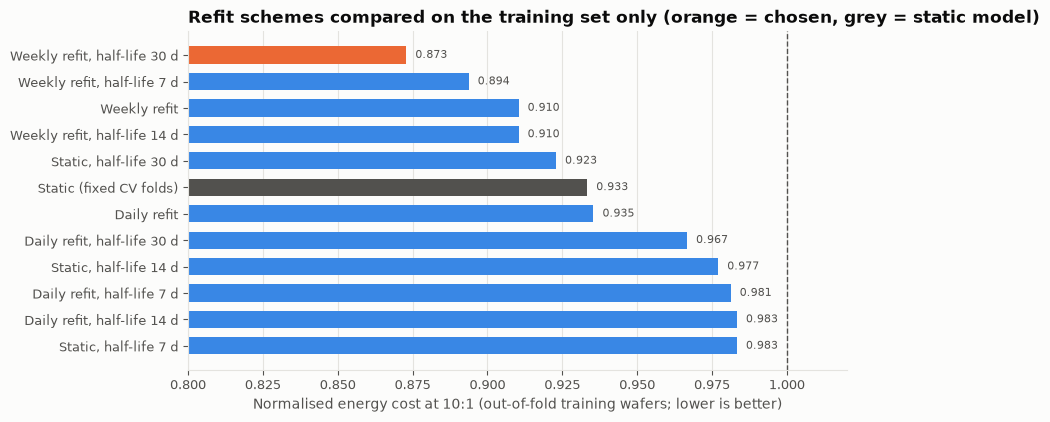

In [3]:
baseline = cand.set_index('candidate').loc['Static (fixed CV folds)']
chosen_name = cand.iloc[0]['candidate']
chosen = cand.iloc[0]
assert chosen['oof_normalized_cost'] < baseline['oof_normalized_cost'], 'no candidate beats the static model'
CH = dict(zip(['W', 'D'], ['Weekly', 'Daily']))
FREQ = 'W' if chosen['refit'] == 'weekly' else 'D'
HALF_LIFE = None if pd.isna(chosen['half_life_days']) else float(chosen['half_life_days'])
print(f'Chosen by the rule: {chosen_name}  (OOF normalised cost {chosen["oof_normalized_cost"]:.3f} vs '
      f'{baseline["oof_normalized_cost"]:.3f} static; PR-AUC {chosen["oof_pr_auc"]:.3f} vs {baseline["oof_pr_auc"]:.3f})')

thresholds = {r: best_threshold(y_oof, oof_scores[chosen_name], c_fn, c_fp)[0] for r, (c_fn, c_fp) in COST_RATIOS.items()}
print('Cost-optimal thresholds on the OOF training scores:', {r: round(t, 4) for r, t in thresholds.items()})

fig, ax = plt.subplots(figsize=(8.5, 4.4))
plot = cand.iloc[::-1]
colors = [CATEGORICAL[1] if n == chosen_name else (REF_LINE_COLOR if n == 'Static (fixed CV folds)' else SEQUENTIAL_BLUES[3])
          for n in plot['candidate']]
ax.barh(plot['candidate'], plot['oof_normalized_cost'], color=colors, height=0.65, zorder=2)
for yy, v in enumerate(plot['oof_normalized_cost']):
    ax.text(v + 0.003, yy, f'{v:.3f}', va='center', fontsize=8, color=TEXT_SECONDARY)
ax.axvline(1.0, color=REF_LINE_COLOR, linestyle='--', linewidth=1)
ax.set_xlim(0.8, 1.02)
ax.set_xlabel('Normalised energy cost at 10:1 (out-of-fold training wafers; lower is better)')
ax.set_title('Refit schemes compared on the training set only (orange = chosen, grey = static model)')
ax.grid(axis='y', visible=False)
save_fig(fig, '07_retraining_cv')
plt.show()

## 2. One evaluation on the test set

The chosen scheme is applied to the 313 test wafers exactly as it would run in the fab: before each week, the
model is refitted on every wafer produced and labelled before that week (training wafers plus earlier test
wafers), and that week's wafers are scored with the threshold fixed in section 1. The static model's test scores
come from 05.

In [4]:
s_test = rolling_scores(rf_pipeline(), X_all, y_all, times, test_pos, freq=FREQ, half_life_days=HALF_LIFE)
from src.retraining import blocks
for tr, sc in blocks(times, test_pos, FREQ):
    print(f'refit before {times.iloc[sc[0]]:%a %d %b}: trained on {len(tr)} wafers -> scores {len(sc)} wafers '
          f'({int(y_all.iloc[sc].sum())} fails)')

static_scores = pd.read_csv(OUTPUTS_DIR / '05_test_scores.csv', index_col=0)['Random forest'].to_numpy()
static_thr = final['thresholds']

res = []
for r, (c_fn, c_fp) in COST_RATIOS.items():
    for label, s, t in [('Static random forest (05)', static_scores, static_thr[r]),
                        (f'Random forest, {chosen_name.lower()}', s_test, thresholds[r])]:
        res.append({'system': label, 'ratio': r, **evaluate(y_test, s, t, c_fn, c_fp)})
test_res = pd.DataFrame(res)
test_res.round(4).to_csv(OUTPUTS_DIR / '07_test_results.csv', index=False)
cols = ['system', 'ratio', 'threshold', 'tp', 'fp', 'fn', 'tn', 'recall', 'precision', 'f2', 'ber', 'roc_auc', 'pr_auc',
        'energy_cost', 'normalized_cost']
print(f'Flag nothing at 10:1 = {flag_nothing_cost(y_test, C_FN):.0f}')
print(test_res[cols].round(3).to_string(index=False))

refit before Thu 02 Oct: trained on 1254 wafers -> scores 81 wafers (8 fails)
refit before Mon 06 Oct: trained on 1335 wafers -> scores 138 wafers (8 fails)
refit before Mon 13 Oct: trained on 1473 wafers -> scores 94 wafers (1 fails)
Flag nothing at 10:1 = 170
                                     system ratio  threshold  tp  fp  fn  tn  recall  precision    f2   ber  roc_auc  pr_auc  energy_cost  normalized_cost
                  Static random forest (05)   5:1      0.722   0   0  17 296   0.000      0.000 0.000 0.500    0.588   0.094         85.0            1.000
Random forest, weekly refit, half-life 30 d   5:1      0.700   0   0  17 296   0.000      0.000 0.000 0.500    0.697   0.149         85.0            1.000
                  Static random forest (05)  10:1      0.467   3  16  14 280   0.176      0.158 0.172 0.439    0.588   0.094        156.0            0.918
Random forest, weekly refit, half-life 30 d  10:1      0.454   7  55  10 241   0.412      0.113 0.269 0.387    0.697  

In [5]:
# Bootstrap (2000 resamples of the 313 test wafers, predictions fixed), 10:1
rng = np.random.default_rng(RANDOM_STATE)
p_new = (s_test >= thresholds['10:1']).astype(int)
p_old = (static_scores >= static_thr['10:1']).astype(int)
B = 2000
bn, bo = np.empty(B), np.empty(B)
for b in range(B):
    i = rng.integers(0, len(y_test), len(y_test)); yb = y_test[i]; base = C_FN * yb.sum()
    bn[b] = (C_FN * ((yb == 1) & (p_new[i] == 0)).sum() + C_FP * ((yb == 0) & (p_new[i] == 1)).sum()) / base
    bo[b] = (C_FN * ((yb == 1) & (p_old[i] == 0)).sum() + C_FP * ((yb == 0) & (p_old[i] == 1)).sum()) / base
boot = {'normalized_cost_ci_low': np.percentile(bn, 2.5), 'normalized_cost_ci_high': np.percentile(bn, 97.5),
        'p_below_flag_nothing': (bn < 1).mean(), 'p_retrained_cheaper_than_static': (bn < bo).mean(),
        'p_tie_with_static': (bn == bo).mean()}
print({k: round(v, 3) for k, v in boot.items()})

{'normalized_cost_ci_low': np.float64(0.644), 'normalized_cost_ci_high': np.float64(1.309), 'p_below_flag_nothing': np.float64(0.688), 'p_retrained_cheaper_than_static': np.float64(0.5), 'p_tie_with_static': np.float64(0.014)}


## 3. Which faults does retraining recover, and what does it cost?

In [6]:
err = pd.DataFrame({'timestamp': times.iloc[test_pos].to_numpy(), 'y': y_test,
                    'p_static': static_scores, 'p_retrained': s_test}, index=test_df.index)
err['static'] = np.where(err['y'] == 1, np.where(p_old == 1, 'TP', 'FN'), np.where(p_old == 1, 'FP', 'TN'))
err['retrained'] = np.where(err['y'] == 1, np.where(p_new == 1, 'TP', 'FN'), np.where(p_new == 1, 'FP', 'TN'))
err.round(4).to_csv(OUTPUTS_DIR / '07_test_scores.csv')
print('Faults: static outcome -> retrained outcome')
print(pd.crosstab(err.loc[err.y == 1, 'static'], err.loc[err.y == 1, 'retrained']).to_string())
burst = err[(err.y == 1) & (err.timestamp >= '2008-10-04') & (err.timestamp < '2008-10-08')]
print(f'\n4-7 October burst: {len(burst)} faults; static caught {int((burst.static == "TP").sum())}, '
      f'retrained caught {int((burst.retrained == "TP").sum())}')
wk = err['timestamp'].dt.to_period('W').dt.start_time.dt.strftime('%d %b')
print('\nBy refit week (retrained system):')
print(pd.crosstab(wk.rename('week starting'), err['retrained']).reindex(columns=['TP', 'FN', 'FP', 'TN'], fill_value=0).to_string())

Faults: static outcome -> retrained outcome
retrained  FN  TP
static           
FN         10   4
TP          0   3

4-7 October burst: 13 faults; static caught 2, retrained caught 6

By refit week (retrained system):
retrained      TP  FN  FP  TN
week starting                
06 Oct          4   4  31  99
13 Oct          1   0   4  89
29 Sep          2   6  20  53


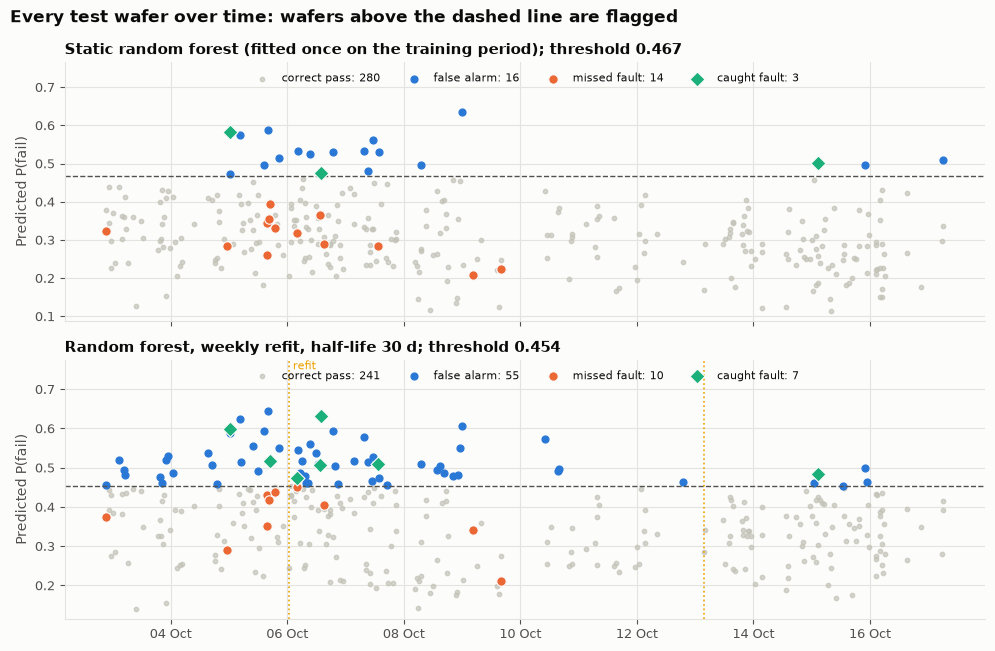

In [7]:
OUT_STYLE = {
    'TN': dict(color='#c3c2b7', s=10, zorder=1, alpha=0.7, label='correct pass'),
    'FP': dict(color=CATEGORICAL[0], s=24, zorder=2, label='false alarm'),
    'FN': dict(color=CATEGORICAL[1], s=46, zorder=3, edgecolor=SURFACE, linewidth=0.8, label='missed fault'),
    'TP': dict(color=CATEGORICAL[2], s=58, zorder=4, edgecolor=SURFACE, linewidth=0.8, marker='D', label='caught fault'),
}
fig, axes = plt.subplots(2, 1, figsize=(10, 6.6), sharex=True)
for ax, col, thr, title in [(axes[0], 'p_static', static_thr['10:1'], 'Static random forest (fitted once on the training period)'),
                            (axes[1], 'p_retrained', thresholds['10:1'], f'Random forest, {chosen_name.lower()}')]:
    oc = 'static' if col == 'p_static' else 'retrained'
    for o in ['TN', 'FP', 'FN', 'TP']:
        d = err[err[oc] == o]
        st = dict(OUT_STYLE[o]); lab = st.pop('label')
        ax.scatter(d['timestamp'], d[col], label=f'{lab}: {len(d)}', **st)
    ax.axhline(thr, color=REF_LINE_COLOR, linestyle='--', linewidth=1)
    ax.set_ylabel('Predicted P(fail)')
    ax.set_title(f'{title}; threshold {thr:.3f}', fontsize=10.5, loc='left')
    ax.set_ylim(top=err[col].max() + 0.13)
    ax.legend(loc='upper center', ncol=4, fontsize=8, frameon=False)
for tr, sc in blocks(times, test_pos, FREQ)[1:]:
    axes[1].axvline(times.iloc[sc[0]], color=CATEGORICAL[3], linewidth=1.2, linestyle=':')
axes[1].text(times.iloc[blocks(times, test_pos, FREQ)[1][1][0]], axes[1].get_ylim()[1], ' refit', color=CATEGORICAL[3],
             fontsize=8, va='top')
axes[1].xaxis.set_major_locator(mdates.DayLocator(interval=2))
axes[1].xaxis.set_major_formatter(mdates.DateFormatter('%d %b'))
fig.suptitle('Every test wafer over time: wafers above the dashed line are flagged', x=0.01, ha='left', fontweight='bold')
fig.tight_layout()
save_fig(fig, '07_test_timeline')
plt.show()

## 4. Energy, emissions and economic value (same assumptions as 06)

E_wafer = 1.432 kWh/cm² × 314.16 cm² = 449.9 kWh; E_inspection = 1% of E_wafer = 4.5 kWh;
detection at 30%, 50% or 70% of the process; grid factor 0.740 kg CO₂e/kWh; electricity valued at RM0.454/kWh;
illustrative line of 10,000 wafers per month. Net saving = TP × E_remaining − FP × E_inspection.

In [8]:
E_WAFER = 1.432 * math.pi * 10 ** 2
E_INSP = 0.01 * E_WAFER
GEF, TARIFF, WAFERS_PER_MONTH, TOOLS_SHARE = 0.740, 0.454, 10_000, 0.404
STAGES = [0.30, 0.50, 0.70]
N_TEST = len(y_test)
r10 = test_res[(test_res.ratio == '10:1')].set_index('system')
new = r10.iloc[1]; old = r10.iloc[0]
TP, FP = int(new['tp']), int(new['fp'])


def net(tp, fp, s, e_insp=E_INSP):
    return tp * (1 - s) * E_WAFER - fp * e_insp


rows = []
for s in STAGES:
    n = net(TP, FP, s); per1000 = n / N_TEST * 1000; annual = per1000 * WAFERS_PER_MONTH * 12 / 1000
    rows.append({'detection_point': f'{s:.0%}', 'E_remaining_kWh': (1 - s) * E_WAFER, 'net_kWh_test': n,
                 'CO2e_kg_test': n * GEF, 'net_kWh_per_1000': per1000, 'RM_per_1000': per1000 * TARIFF,
                 'annual_MWh': annual / 1000, 'annual_RM': annual * TARIFF, 'annual_t_CO2e': annual * GEF / 1000,
                 'annual_MWh_process_tools_only': annual * TOOLS_SHARE / 1000,
                 'static_net_kWh_test': net(int(old['tp']), int(old['fp']), s),
                 'perfect_net_kWh_test': net(int(y_test.sum()), 0, s),
                 'breakeven_E_inspection_kWh': TP * (1 - s) * E_WAFER / FP,
                 'kWh_per_inspection': n / (TP + FP), 'inspect_all_net_kWh': net(int(y_test.sum()), N_TEST - int(y_test.sum()), s)})
energy = pd.DataFrame(rows)
energy['share_of_perfect'] = energy['net_kWh_test'] / energy['perfect_net_kWh_test']
energy['inspect_all_kWh_per_inspection'] = energy['inspect_all_net_kWh'] / N_TEST
energy.round(3).to_csv(OUTPUTS_DIR / '07_energy_savings.csv', index=False)
pd.set_option('display.width', 220)
print(f'TP {TP}, FP {FP}; flagged {TP + FP} of {N_TEST} ({(TP + FP) / N_TEST:.1%}); break-even precision '
      + ', '.join(f'{E_INSP / ((1 - s) * E_WAFER + E_INSP):.1%}' for s in STAGES))
print(energy.round(1).T.to_string())
print(f'\nInspection workload at {WAFERS_PER_MONTH:,} wafers/month: {(TP + FP) / N_TEST * WAFERS_PER_MONTH:,.0f} flags, '
      f'{FP / N_TEST * WAFERS_PER_MONTH:,.0f} on good wafers')

TP 7, FP 55; flagged 62 of 313 (19.8%); break-even precision 1.4%, 2.0%, 3.2%
                                       0         1         2
detection_point                      30%       50%       70%
E_remaining_kWh                    314.9     224.9     135.0
net_kWh_test                      1957.0    1327.1     697.3
CO2e_kg_test                      1448.2     982.1     516.0
net_kWh_per_1000                  6252.3    4240.0    2227.8
RM_per_1000                       2838.5    1925.0    1011.4
annual_MWh                         750.3     508.8     267.3
annual_RM                       340623.7  230997.7  121371.7
annual_t_CO2e                      555.2     376.5     197.8
annual_MWh_process_tools_only      303.1     205.6     108.0
static_net_kWh_test                872.8     602.8     332.9
perfect_net_kWh_test              5353.5    3823.9    2294.4
breakeven_E_inspection_kWh          40.1      28.6      17.2
kWh_per_inspection                  31.6      21.4      11.2
inspect

                            TP   FP  E_saved @ 30% (kWh)  E_saved @ 50% (kWh)  E_saved @ 70% (kWh)
policy                                                                                            
Perfect detector            17    0               5354.0               3824.0               2294.0
Static random forest, 10:1   3   16                873.0                603.0                333.0
Retrained, 10:1 threshold    7   55               1957.0               1327.0                697.0
Retrained, 20:1 threshold   15  210               3779.0               2429.0               1080.0


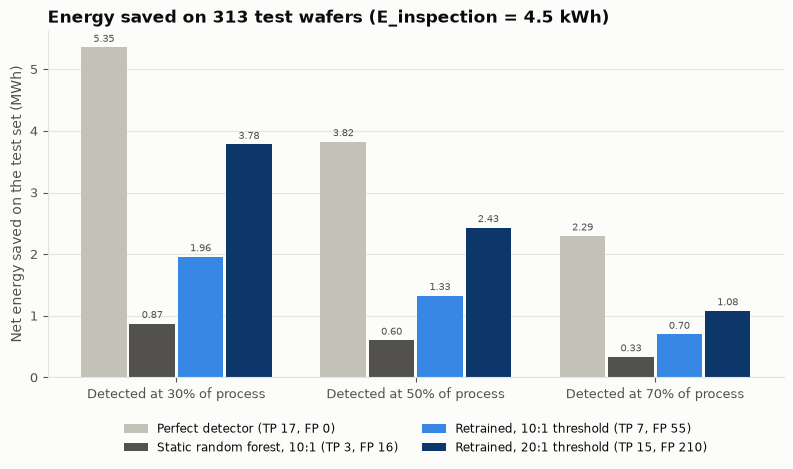

In [9]:
# Context figure: perfect detector, static model (10:1) and retrained system at its 5:1 / 10:1 / 20:1 thresholds
ctx = [('Perfect detector', int(y_test.sum()), 0), ('Static random forest, 10:1', int(old['tp']), int(old['fp']))] + \
      [(f'Retrained, {r} threshold', int(test_res[(test_res.ratio == r)].iloc[1]['tp']),
        int(test_res[(test_res.ratio == r)].iloc[1]['fp'])) for r in ('10:1', '20:1')]   # 5:1 flags nothing
ctx_df = pd.DataFrame([{'policy': p, 'TP': tp, 'FP': fp, **{f'E_saved @ {s:.0%} (kWh)': net(tp, fp, s) for s in STAGES}}
                       for p, tp, fp in ctx]).set_index('policy')
ctx_df.round(1).to_csv(OUTPUTS_DIR / '07_energy_context.csv')
print(ctx_df.round(0).to_string())

fig, ax = plt.subplots(figsize=(9.5, 4.5))
colors = ['#c3c2b7', REF_LINE_COLOR, SEQUENTIAL_BLUES[3], SEQUENTIAL_BLUES[6]]
x = np.arange(len(STAGES)); w = 0.19
for j, (p, c) in enumerate(zip(ctx_df.index, colors)):
    vals = [ctx_df.loc[p, f'E_saved @ {s:.0%} (kWh)'] / 1000 for s in STAGES]
    pos = x + (j - 1.5) * (w + 0.012)
    ax.bar(pos, vals, width=w, color=c, zorder=2, label=f"{p} (TP {ctx_df.loc[p, 'TP']}, FP {ctx_df.loc[p, 'FP']})")
    for pp, v in zip(pos, vals):
        ax.text(pp, v + 0.05, f'{v:.2f}', ha='center', va='bottom', fontsize=7.5, color=TEXT_SECONDARY)
ax.set_xticks(x, [f'Detected at {s:.0%} of process' for s in STAGES])
ax.set_ylabel('Net energy saved on the test set (MWh)')
ax.set_title(f'Energy saved on {N_TEST} test wafers (E_inspection = {E_INSP:.1f} kWh)')
ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.1), ncol=2, fontsize=8.5)
ax.grid(axis='x', visible=False)
save_fig(fig, '07_energy_savings')
plt.show()

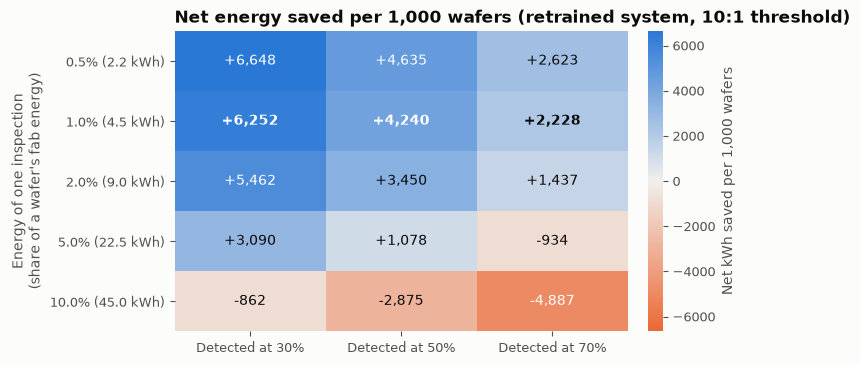

Positive in 11 of 15 combinations


In [10]:
# Sensitivity: net kWh per 1,000 wafers vs inspection energy and detection point (retrained system, 10:1)
fracs = [0.005, 0.01, 0.02, 0.05, 0.10]
grid = np.array([[net(TP, FP, s, f * E_WAFER) / N_TEST * 1000 for s in STAGES] for f in fracs])
pd.DataFrame(grid, index=[f'{f:.1%}' for f in fracs], columns=[f'{s:.0%}' for s in STAGES]).round(0) \
    .to_csv(OUTPUTS_DIR / '07_energy_sensitivity.csv')
lim = np.abs(grid).max()
cmap = LinearSegmentedColormap.from_list('div', [FAIL_COLOR, '#f0efec', PASS_COLOR])
fig, ax = plt.subplots(figsize=(6.4, 3.9))
im = ax.imshow(grid, cmap=cmap, vmin=-lim, vmax=lim, aspect='auto')
ax.set_xticks(range(3), [f'Detected at {s:.0%}' for s in STAGES])
ax.set_yticks(range(5), [f'{f:.1%} ({f * E_WAFER:.1f} kWh)' for f in fracs])
for i in range(5):
    for j in range(3):
        v = grid[i, j]
        ax.text(j, i, f'{v:+,.0f}', ha='center', va='center', fontsize=10,
                color='white' if abs(v) > 0.6 * lim else TEXT_PRIMARY, fontweight='bold' if i == 1 else 'normal')
ax.set_ylabel("Energy of one inspection\n(share of a wafer's fab energy)")
ax.grid(False)
for sp in ax.spines.values():
    sp.set_visible(False)
cb = fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04); cb.outline.set_visible(False)
cb.set_label('Net kWh saved per 1,000 wafers', color=TEXT_SECONDARY)
ax.set_title('Net energy saved per 1,000 wafers (retrained system, 10:1 threshold)')
save_fig(fig, '07_energy_sensitivity')
plt.show()
print(f'Positive in {(grid > 0).sum()} of {grid.size} combinations')

## 5. Save the final system

In [11]:
system = {
    'model': 'Random forest', 'file_static': final['file'], 'imbalance': 'Class weights',
    'retraining': {'refit': chosen['refit'], 'half_life_days': HALF_LIFE,
                   'rule': 'before each block, refit on every wafer produced and labelled earlier; recency weight 0.5**(age/half_life)'},
    'thresholds': thresholds,
    'selection': 'lowest OOF normalised energy cost at 10:1 among the candidates in 07_retraining_cv.csv (training set only)',
    'test_10to1': {k: (round(float(v), 4) if isinstance(v, (float, np.floating)) else int(v) if isinstance(v, (np.integer,)) else v)
                   for k, v in new.items() if k != 'ratio'},
    'bootstrap_10to1': {k: round(float(v), 4) for k, v in boot.items()},
}
(MODELS_DIR / 'final_system.json').write_text(json.dumps(system, indent=2, default=str))
print(json.dumps(system, indent=2, default=str))

{
  "model": "Random forest",
  "file_static": "outputs/models/random_forest.joblib",
  "imbalance": "Class weights",
  "retraining": {
    "refit": "weekly",
    "half_life_days": 30.0,
    "rule": "before each block, refit on every wafer produced and labelled earlier; recency weight 0.5**(age/half_life)"
  },
  "thresholds": {
    "5:1": 0.70003413662841,
    "10:1": 0.45371315279330143,
    "20:1": 0.3000912993631416
  },
  "selection": "lowest OOF normalised energy cost at 10:1 among the candidates in 07_retraining_cv.csv (training set only)",
  "test_10to1": {
    "threshold": 0.4537,
    "recall": 0.4118,
    "precision": 0.1129,
    "f1": 0.1772,
    "f2": 0.2692,
    "ber": 0.387,
    "roc_auc": 0.6967,
    "pr_auc": 0.1489,
    "accuracy": 0.7923,
    "energy_cost": 155.0,
    "normalized_cost": 0.9118,
    "tp": 7,
    "fp": 55,
    "fn": 10,
    "tn": 241
  },
  "bootstrap_10to1": {
    "normalized_cost_ci_low": 0.6444,
    "normalized_cost_ci_high": 1.3091,
    "p_below_fla

### Verdict

Weekly refitting with a 30-day recency half-life was chosen on the training set alone and then scored once on
the test set. Read the printed results above for the exact numbers. In short: refitting **recovers part of the
October burst** and roughly **doubles the number of faults caught**, and it ranks test wafers clearly better
(higher PR-AUC and ROC-AUC). The price is many more false alarms, so the 10 : 1 cost is only slightly lower
than the static model's, while the energy estimate, which values a false alarm at one inspection, rises
substantially. Missed faults remain, and the saving is still not statistically certain.